# Scenario Analysis of a Delta-Hedged Option on the Squared Spread
## Worst-case and weighted scenario risk measures over 3,888 scenarios

We are long one European option paying $\bigl(S^{(1)}_T-S^{(2)}_T\bigr)^2$ at $T$ and
short the two-dimensional Black–Scholes delta hedge. Over a five-day horizon the share
holdings are frozen. This notebook revalues the position under every combination of
five-day log returns, volatility shocks and correlation shocks on the assignment's grid,
$N=6\cdot6\cdot6\cdot6\cdot3=3{,}888$ scenarios, and reports the worst-case scenario
risk measure and the weighted scenario risk measure together with the scenarios that
attain them.

**Price and deltas** (derived by hand in the written part), with $\tau=T-t$:

$$V(t,s_1,s_2;\sigma,\rho)=e^{r\tau}\Bigl(s_1^2e^{\sigma_1^2\tau}-2s_1s_2e^{\sigma_1\sigma_2\rho\tau}+s_2^2e^{\sigma_2^2\tau}\Bigr),$$

$$h^{(1)}=\partial_{s_1}V=2e^{r\tau}\bigl(s_1e^{\sigma_1^2\tau}-s_2e^{\sigma_1\sigma_2\rho\tau}\bigr),\qquad
h^{(2)}=\partial_{s_2}V=2e^{r\tau}\bigl(s_2e^{\sigma_2^2\tau}-s_1e^{\sigma_1\sigma_2\rho\tau}\bigr).$$

**Portfolio and loss.** $V_t=V(t,S^{(1)}_t,S^{(2)}_t;\sigma_t,\rho_t)-h^{(1)}_tS^{(1)}_t-h^{(2)}_tS^{(2)}_t$,
and in scenario $x_n=(x_1,x_2,\sigma'_1,\sigma'_2,\rho')$, with $S^{(i)}_{t+5\Delta}=S^{(i)}_te^{x_i}$,

$$\ell_n=-\Bigl(V\bigl(t+5\Delta,S^{(1)}_te^{x_1},S^{(2)}_te^{x_2};\sigma',\rho'\bigr)-h^{(1)}_tS^{(1)}_te^{x_1}-h^{(2)}_tS^{(2)}_te^{x_2}-V_t\Bigr).$$

**Risk measures** (lecture 6): worst case $\max_n\ell_n$; weighted $\Psi_{x,w}=\max_n w_n\ell_n$.

---
## 1. Imports

In [1]:
import sys
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

print("python     ", sys.version.split()[0])
print("numpy      ", np.__version__)
print("pandas     ", pd.__version__)
print("matplotlib ", matplotlib.__version__)

python      3.13.16
numpy       2.5.3
pandas      3.0.5
matplotlib  3.11.2


---
## 2. Parameters

| Symbol | Meaning | Value |
|---|---|---|
| $r$ | risk-free rate | 1.32% |
| $\mu_1,\ \mu_2$ | physical drifts | 15.475%, 18.312% |
| $\sigma_{1,t},\ \sigma_{2,t}$ | volatilities estimated at $t=0$ | 22.14%, 30.36% |
| $\rho_t$ | correlation estimated at $t=0$ | 0.237 |
| $T$ | maturity | 0.25 |
| $S^{(1)}_0,\ S^{(2)}_0$ | stock prices | 158.12, 170.33 |
| $\Delta$ | one day | $1/252$ |
| — | horizon | $5\Delta$ |

The drifts $\mu_1,\mu_2$ do not enter the calculation: the scenarios fix the five-day
log returns directly, and the option is priced under $\mathbb Q$, where both stocks
drift at $r$.

In [2]:
R      = 0.0132
MU     = (0.15475, 0.18312)        # not used: scenarios fix the log returns directly
SIG_T  = np.array([0.2214, 0.3036])
RHO_T  = 0.237
T_MAT  = 0.25
T0     = 0.0
S_T    = np.array([158.12, 170.33])
DT     = 1.0 / 252.0
H_DAYS = 5

TAU0 = T_MAT - T0                  # time to maturity at t
TAU1 = T_MAT - (T0 + H_DAYS * DT)  # time to maturity at t + 5 Delta

FIG1 = Path("scenario_loss_by_vol_corr.png")
FIG2 = Path("scenario_loss_by_returns.png")

C_INK, C_MUTE = "#0b0b0b", "#8a8a85"
DIVERGING = LinearSegmentedColormap.from_list("gain_loss", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 11,
    "axes.titlesize": 12.5, "axes.labelsize": 11, "legend.frameon": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
})
print(f"tau at t = {TAU0:.6f},  tau at t + 5 Delta = {TAU1:.6f}")

tau at t = 0.250000,  tau at t + 5 Delta = 0.230159


---
## 3. Option price and deltas — part (a)

The closed form above comes from the second moments of correlated lognormals under
$\mathbb Q$ (handwritten part). Three checks below: a Monte-Carlo evaluation of the
risk-neutral expectation $\mathbb E^{\mathbb Q}\bigl[e^{-r\tau}(S^{(1)}_T-S^{(2)}_T)^2\bigr]$,
finite-difference deltas, and Euler's identity. $V$ is homogeneous of degree 2 in
$(s_1,s_2)$, so $s_1\partial_{s_1}V+s_2\partial_{s_2}V=2V$, and therefore the hedged
portfolio is worth exactly $V_t=V-2V=-V(t,S_t)$.

### Pseudocode — price and deltas

```
INPUT : t, s1, s2, sigma1, sigma2, rho, r, T
OUTPUT: option value V and deltas h1, h2

1  tau <- T - t
2  a <- exp(sigma1^2 tau);  b <- exp(sigma1 sigma2 rho tau);  c <- exp(sigma2^2 tau)
3  V  <- exp(r tau) (s1^2 a - 2 s1 s2 b + s2^2 c)
4  h1 <- 2 exp(r tau) (s1 a - s2 b);   h2 <- 2 exp(r tau) (s2 c - s1 b)
```

In [3]:
def option_value(tau, s1, s2, sig1, sig2, rho):
    """V = e^{r tau} (s1^2 e^{sig1^2 tau} - 2 s1 s2 e^{sig1 sig2 rho tau} + s2^2 e^{sig2^2 tau})."""
    return np.exp(R * tau) * (s1 ** 2 * np.exp(sig1 ** 2 * tau)
                              - 2 * s1 * s2 * np.exp(sig1 * sig2 * rho * tau)
                              + s2 ** 2 * np.exp(sig2 ** 2 * tau))


def option_deltas(tau, s1, s2, sig1, sig2, rho):
    b = np.exp(sig1 * sig2 * rho * tau)
    h1 = 2 * np.exp(R * tau) * (s1 * np.exp(sig1 ** 2 * tau) - s2 * b)
    h2 = 2 * np.exp(R * tau) * (s2 * np.exp(sig2 ** 2 * tau) - s1 * b)
    return h1, h2


V0 = float(option_value(TAU0, *S_T, *SIG_T, RHO_T))
H1, H2 = (float(h) for h in option_deltas(TAU0, *S_T, *SIG_T, RHO_T))
PORT_T = V0 - H1 * S_T[0] - H2 * S_T[1]
print(f"V(t, S_t; sigma_t, rho_t) = {V0:.6f}")
print(f"h1 = {H1:.6f}   (short -h1 = {-H1:.6f} shares of stock 1, i.e. LONG {abs(H1):.4f})")
print(f"h2 = {H2:.6f}   (short {H2:.6f} shares of stock 2)")
print(f"portfolio value V_t = V - h1 S1 - h2 S2 = {PORT_T:.6f}   (= -V, Euler's identity)")

# check 1: Monte Carlo of the risk-neutral expectation
rng = np.random.default_rng(731)
n_mc = 2_000_000
z1, z2 = rng.standard_normal(n_mc), rng.standard_normal(n_mc)
w1 = np.sqrt(TAU0) * z1
w2 = np.sqrt(TAU0) * (RHO_T * z1 + np.sqrt(1 - RHO_T ** 2) * z2)
ST1 = S_T[0] * np.exp((R - 0.5 * SIG_T[0] ** 2) * TAU0 + SIG_T[0] * w1)
ST2 = S_T[1] * np.exp((R - 0.5 * SIG_T[1] ** 2) * TAU0 + SIG_T[1] * w2)
pay = np.exp(-R * TAU0) * (ST1 - ST2) ** 2
mc, se = pay.mean(), pay.std(ddof=1) / np.sqrt(n_mc)
print(f"\nMonte Carlo E^Q[e^(-r tau)(S1_T - S2_T)^2] = {mc:.4f} +/- {1.96 * se:.4f} (95%)   closed form {V0:.4f}")
assert abs(mc - V0) < 4 * se

# check 2: finite-difference deltas
eps = 1e-4
fd1 = (option_value(TAU0, S_T[0] + eps, S_T[1], *SIG_T, RHO_T) - option_value(TAU0, S_T[0] - eps, S_T[1], *SIG_T, RHO_T)) / (2 * eps)
fd2 = (option_value(TAU0, S_T[0], S_T[1] + eps, *SIG_T, RHO_T) - option_value(TAU0, S_T[0], S_T[1] - eps, *SIG_T, RHO_T)) / (2 * eps)
print(f"finite-difference deltas: {float(fd1):.6f}, {float(fd2):.6f}")
assert abs(fd1 - H1) < 1e-6 and abs(fd2 - H2) < 1e-6
assert abs(PORT_T + V0) < 1e-9

V(t, S_t; sigma_t, rho_t) = 921.739866
h1 = -21.952543   (short -h1 = 21.952543 shares of stock 1, i.e. LONG 21.9525)
h2 = 31.201877   (short 31.201877 shares of stock 2)
portfolio value V_t = V - h1 S1 - h2 S2 = -921.739866   (= -V, Euler's identity)

Monte Carlo E^Q[e^(-r tau)(S1_T - S2_T)^2] = 921.1235 +/- 1.9757 (95%)   closed form 921.7399
finite-difference deltas: -21.952543, 31.201877


---
## 4. The scenario grid and the weights

Each scenario fixes five quantities at $t+5\Delta$:

| risk factor | values | weights |
|---|---|---|
| $X^{(i)}_{t+5\Delta}$, $i=1,2$ | $\pm0.20,\ \pm0.10,\ \pm0.05$ | 0.5, 0.75, 1 |
| $\sigma^{(i)}_{t+5\Delta}/\sigma^{(i)}_t$, $i=1,2$ | $\{0.5,2\},\ \{0.75,1.75\},\ \{1.25,1.5\}$ | 0.5, 1.25, 0.75 |
| $\rho_{t+5\Delta}-\rho_t$ | $0,\ \pm0.5$ | 0.5, 1.25 |

so $N=6^4\times3=3{,}888$, and a scenario's weight is the product of its five factor
weights. Since $\rho_t=0.237$, the shocked correlations $-0.263$ and $0.737$ stay in
$(-1,1)$. The option is repriced with $\tau=T-5\Delta$ and the new $(\sigma,\rho)$.

### Pseudocode — scenarios, losses and the two risk measures

```
INPUT : the five value lists and their weights; S_t, sigma_t, rho_t, h1, h2, V_t
OUTPUT: losses l_n, weighted losses w_n l_n, and the two maximisers

 1  for every (x1, x2, k1, k2, d) in the Cartesian product of the five lists:     (3,888)
 2        S1' <- S1_t exp(x1);  S2' <- S2_t exp(x2)
 3        sigma1' <- k1 sigma1_t;  sigma2' <- k2 sigma2_t;  rho' <- rho_t + d
 4        V'  <- option value at (t + 5 Delta, S1', S2'; sigma1', sigma2', rho')
 5        l_n <- -( V' - h1 S1' - h2 S2' - V_t )                 (hedge frozen at t)
 6        w_n <- w(x1) w(x2) w(k1) w(k2) w(d)
 7  worst case: n* <- argmax l_n,        report l_n* and scenario n*          (part b)
 8  weighted:   m* <- argmax w_n l_n,    report w_m* l_m*, l_m*, scenario m*  (part c)
 9  check that each maximiser is unique
```

In [4]:
X_VALS   = [-0.20, -0.10, -0.05, 0.05, 0.10, 0.20]
K_VALS   = [0.5, 0.75, 1.25, 1.5, 1.75, 2.0]
D_VALS   = [-0.5, 0.0, 0.5]
W_X      = {0.20: 0.5, 0.10: 0.75, 0.05: 1.0}
W_K      = {0.5: 0.5, 2.0: 0.5, 0.75: 1.25, 1.75: 1.25, 1.25: 0.75, 1.5: 0.75}
W_D      = {0.0: 0.5, 0.5: 1.25, -0.5: 1.25}

grid = pd.DataFrame(list(itertools.product(X_VALS, X_VALS, K_VALS, K_VALS, D_VALS)),
                    columns=["x1", "x2", "k1", "k2", "drho"])
grid["w"] = (grid.x1.abs().round(2).map(W_X) * grid.x2.abs().round(2).map(W_X)
             * grid.k1.map(W_K) * grid.k2.map(W_K) * grid.drho.map(W_D))
print(f"N = {len(grid):,} scenarios;  weights range from {grid.w.min():.6f} to {grid.w.max():.6f}")

# the sheet's worked example: x1 = -0.1, x2 = 0.2, sigma1 = 2 sigma1_t, sigma2 = 0.5 sigma2_t, drho = -0.5
ex = grid[(grid.x1 == -0.10) & (grid.x2 == 0.20) & (grid.k1 == 2.0) & (grid.k2 == 0.5) & (grid.drho == -0.5)]
print(f"weight of the sheet's example scenario: {float(ex.w.iloc[0]):.7f}  (15/128 = {15/128:.7f})")
assert len(grid) == 3888 and grid.w.notna().all() and abs(float(ex.w.iloc[0]) - 15 / 128) < 1e-12

N = 3,888 scenarios;  weights range from 0.031250 to 1.953125
weight of the sheet's example scenario: 0.1171875  (15/128 = 0.1171875)


---
## 5. Losses in every scenario

In [5]:
def scenario_loss(x1, x2, k1, k2, drho):
    s1n, s2n = S_T[0] * np.exp(x1), S_T[1] * np.exp(x2)
    v_new = option_value(TAU1, s1n, s2n, k1 * SIG_T[0], k2 * SIG_T[1], RHO_T + drho)
    port_new = v_new - H1 * s1n - H2 * s2n
    return -(port_new - PORT_T)


grid["loss"] = scenario_loss(grid.x1.to_numpy(), grid.x2.to_numpy(), grid.k1.to_numpy(),
                             grid.k2.to_numpy(), grid.drho.to_numpy())
grid["wloss"] = grid.w * grid.loss
grid["sigma1"] = grid.k1 * SIG_T[0]
grid["sigma2"] = grid.k2 * SIG_T[1]
grid["rho"] = RHO_T + grid.drho

print(f"losses: min {grid.loss.min():,.2f}  median {grid.loss.median():,.2f}  max {grid.loss.max():,.2f}")
print(f"share of scenarios with a loss (> 0): {(grid.loss > 0).mean():.1%}")

losses: min -8,959.53  median -1,382.49  max 1,000.36
share of scenarios with a loss (> 0): 12.1%


---
## 6. Part (b): worst-case scenario risk measure

$\rho(L_{t+5\Delta})=\max\{\ell_n:n=1,\dots,N\}$, all scenarios weighted equally.

In [6]:
cols = ["x1", "x2", "k1", "k2", "sigma1", "sigma2", "drho", "rho", "loss", "w", "wloss"]
i_star = int(grid.loss.idxmax())
worst = grid.loc[i_star]
n_ties = int(np.isclose(grid.loss, worst.loss, rtol=0, atol=1e-9).sum())
print("WORST-CASE SCENARIO")
print(f"  rho(L) = max_n l_n = {worst.loss:.4f}    (attained by {n_ties} scenario)")
print(f"  X1 = {worst.x1:+.2f}, X2 = {worst.x2:+.2f}")
print(f"  sigma1 = {worst.k1} x sigma1_t = {worst.sigma1:.4f},  sigma2 = {worst.k2} x sigma2_t = {worst.sigma2:.4f}")
print(f"  rho = rho_t {worst.drho:+.1f} = {worst.rho:.3f}")
print("\nten largest losses")
print(grid.sort_values("loss", ascending=False)[cols].head(10).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

WORST-CASE SCENARIO
  rho(L) = max_n l_n = 1000.3617    (attained by 1 scenario)
  X1 = +0.20, X2 = +0.20
  sigma1 = 0.5 x sigma1_t = 0.1107,  sigma2 = 0.5 x sigma2_t = 0.1518
  rho = rho_t +0.5 = 0.737

ten largest losses


    x1     x2     k1     k2  sigma1  sigma2   drho    rho      loss      w    wloss
0.2000 0.2000 0.5000 0.5000  0.1107  0.1518 0.5000 0.7370 1000.3617 0.0781  78.1533
0.2000 0.2000 0.7500 0.5000  0.1661  0.1518 0.5000 0.7370  983.1422 0.1953 192.0200
0.2000 0.2000 0.7500 0.7500  0.1661  0.2277 0.5000 0.7370  866.0816 0.4883 422.8914
0.1000 0.1000 0.5000 0.5000  0.1107  0.1518 0.5000 0.7370  845.8243 0.1758 148.6800
0.2000 0.2000 0.5000 0.5000  0.1107  0.1518 0.0000 0.2370  844.1980 0.0312  26.3812
0.1000 0.1000 0.7500 0.5000  0.1661  0.1518 0.5000 0.7370  831.7261 0.4395 365.5046
0.2000 0.2000 0.5000 0.7500  0.1107  0.2277 0.5000 0.7370  825.3497 0.1953 161.2011
0.2000 0.2000 1.2500 0.5000  0.2767  0.1518 0.5000 0.7370  787.0370 0.1172  92.2309
0.2000 0.2000 1.2500 0.7500  0.2767  0.2277 0.5000 0.7370  786.4988 0.2930 230.4196
0.0500 0.0500 0.5000 0.5000  0.1107  0.1518 0.5000 0.7370  772.1355 0.3125 241.2924


---
## 7. Part (c): weighted scenario risk measure

$\Psi_{x,w}=\max\{w_n\ell_n:n=1,\dots,N\}$ with the product weights of section 4.

In [7]:
j_star = int(grid.wloss.idxmax())
best_w = grid.loc[j_star]
n_ties_w = int(np.isclose(grid.wloss, best_w.wloss, rtol=0, atol=1e-9).sum())
print("WEIGHTED SCENARIO RISK MEASURE")
print(f"  Psi = max_n w_n l_n = {best_w.wloss:.4f}    (attained by {n_ties_w} scenario)")
print(f"  X1 = {best_w.x1:+.2f}, X2 = {best_w.x2:+.2f}")
print(f"  sigma1 = {best_w.k1} x sigma1_t = {best_w.sigma1:.4f},  sigma2 = {best_w.k2} x sigma2_t = {best_w.sigma2:.4f}")
print(f"  rho = rho_t {best_w.drho:+.1f} = {best_w.rho:.3f}")
print(f"  weight w = {best_w.w:.6f}  (= 1 x 1 x 1.25 x 1.25 x 1.25 = {1.25**3:.6f})")
print(f"  portfolio loss in this scenario: l = {best_w.loss:.4f}")
print(f"\n  its rank among the unweighted losses: {int((grid.loss > best_w.loss).sum()) + 1} of {len(grid):,}")
print(f"  with weights rescaled to (0, 1] by the largest weight ({grid.w.max():.6f}), "
      f"Psi = {best_w.wloss / grid.w.max():.4f} and the maximiser is unchanged")
print("\nten largest weighted losses")
print(grid.sort_values("wloss", ascending=False)[cols].head(10).to_string(index=False, float_format=lambda v: f"{v:.4f}"))

WEIGHTED SCENARIO RISK MEASURE
  Psi = max_n w_n l_n = 1313.7859    (attained by 1 scenario)
  X1 = +0.05, X2 = +0.05
  sigma1 = 0.75 x sigma1_t = 0.1661,  sigma2 = 0.75 x sigma2_t = 0.2277
  rho = rho_t +0.5 = 0.737
  weight w = 1.953125  (= 1 x 1 x 1.25 x 1.25 x 1.25 = 1.953125)
  portfolio loss in this scenario: l = 672.6584

  its rank among the unweighted losses: 21 of 3,888
  with weights rescaled to (0, 1] by the largest weight (1.953125), Psi = 672.6584 and the maximiser is unchanged

ten largest weighted losses
     x1      x2     k1     k2  sigma1  sigma2   drho    rho     loss      w     wloss
 0.0500  0.0500 0.7500 0.7500  0.1661  0.2277 0.5000 0.7370 672.6584 1.9531 1313.7859
-0.0500 -0.0500 0.7500 0.7500  0.1661  0.2277 0.5000 0.7370 550.5175 1.9531 1075.2294
 0.1000  0.0500 0.7500 0.7500  0.1661  0.2277 0.5000 0.7370 633.3088 1.4648  927.6984
 0.0500  0.1000 0.7500 0.7500  0.1661  0.2277 0.5000 0.7370 617.2600 1.4648  904.1894
 0.1000  0.1000 0.7500 0.7500  0.1661  0.227

---
## 8. What drives the losses

Split each loss into a **market-move** part (new prices and the shorter maturity, with
$\sigma,\rho$ still at their time-$t$ values) and a **parameter** part (the remaining
change in option value when $\sigma,\rho$ are re-estimated):

$$\ell=\underbrace{-\bigl(V(\tau_1,S';\sigma_t,\rho_t)-h\cdot S'-V_t\bigr)}_{\text{market move}}
\;\underbrace{-\bigl(V(\tau_1,S';\sigma',\rho')-V(\tau_1,S';\sigma_t,\rho_t)\bigr)}_{\text{volatility and correlation}} .$$

The position is long the option and delta-hedged, so it is long gamma **on the spread**:
moves that push the two stocks apart produce large gains. When both stocks move by the
same log return $x$, homogeneity gives $V\to e^{2x}V$ while the hedge moves by $e^{x}$, so
the gamma gain is only about $V(e^{x}-1)^2$ and five days of time decay (scaled by
$e^{2x}$) can outweigh it — the market-move part is therefore small, and positive only
near $x_1=x_2$. The large losses come from re-estimating the parameters: the option is
long vega on the spread $S^{(1)}-S^{(2)}$, a long–short combination, so it loses value
when volatilities fall and when the correlation rises (lecture 6: for a long–short
position $\theta^\top\Sigma\theta$ is decreasing in $\rho$).

In [8]:
def split(row):
    s1n, s2n = S_T[0] * np.exp(row.x1), S_T[1] * np.exp(row.x2)
    v_old = option_value(TAU1, s1n, s2n, *SIG_T, RHO_T)
    v_new = option_value(TAU1, s1n, s2n, row.sigma1, row.sigma2, row.rho)
    market = -(v_old - H1 * s1n - H2 * s2n - PORT_T)
    param = -(v_new - v_old)
    return market, param


print(f"{'':<26}{'market move':>14}{'vol & corr':>14}{'total loss':>14}")
for lab, row in (("worst case (b)", worst), ("weighted maximiser (c)", best_w)):
    m_, p_ = split(row)
    print(f"{lab:<26}{m_:>14.4f}{p_:>14.4f}{m_ + p_:>14.4f}")
    assert abs(m_ + p_ - row.loss) < 1e-9

no_move = -(option_value(TAU1, *S_T, *SIG_T, RHO_T) - H1 * S_T[0] - H2 * S_T[1] - PORT_T)
print(f"\nreference: no price move, no parameter change, five days pass -> loss {no_move:.4f} (time decay)")
pairs = grid.drop_duplicates(["x1", "x2"])
mk = np.array([split(r_)[0] for r_ in pairs[["x1", "x2", "sigma1", "sigma2", "rho"]].itertuples()])
print(f"market-move part over the 36 return pairs: from {mk.min():.2f} (stocks move apart: a gain)"
      f" to {mk.max():.2f}")
print(f"  pairs with a market-move loss: {[(float(a), float(b)) for a, b in pairs[['x1', 'x2']][mk > 0].to_numpy()]}")

                             market move    vol & corr    total loss
worst case (b)                   47.5911      952.7706     1000.3617
weighted maximiser (c)           66.3057      606.3527      672.6584

reference: no price move, no parameter change, five days pass -> loss 62.1883 (time decay)
market-move part over the 36 return pairs: from -4389.67 (stocks move apart: a gain) to 66.31
  pairs with a market-move loss: [(-0.2, -0.2), (-0.1, -0.1), (-0.1, -0.05), (-0.05, -0.05), (0.05, 0.05), (0.1, 0.05), (0.1, 0.1), (0.2, 0.2)]


---
## 9. Figures

### Pseudocode — loss by volatility and correlation shock

```
1  for each correlation shock d in {-0.5, 0, +0.5} (one panel each):
2        for each pair of volatility multipliers (k1, k2): the largest loss over the 36 return pairs
3  draw the 6 x 6 values as a heat map with a diverging scale centred at zero (gain blue, loss red)
4  print each value in its cell; mark the cell of the overall worst case
```

### Pseudocode — loss by log returns at the worst-case parameters

```
1  fix (k1, k2, d) at the worst-case values
2  draw the 6 x 6 losses over (x1, x2) as a heat map with the same diverging scale
3  print each value in its cell; mark the worst case
```

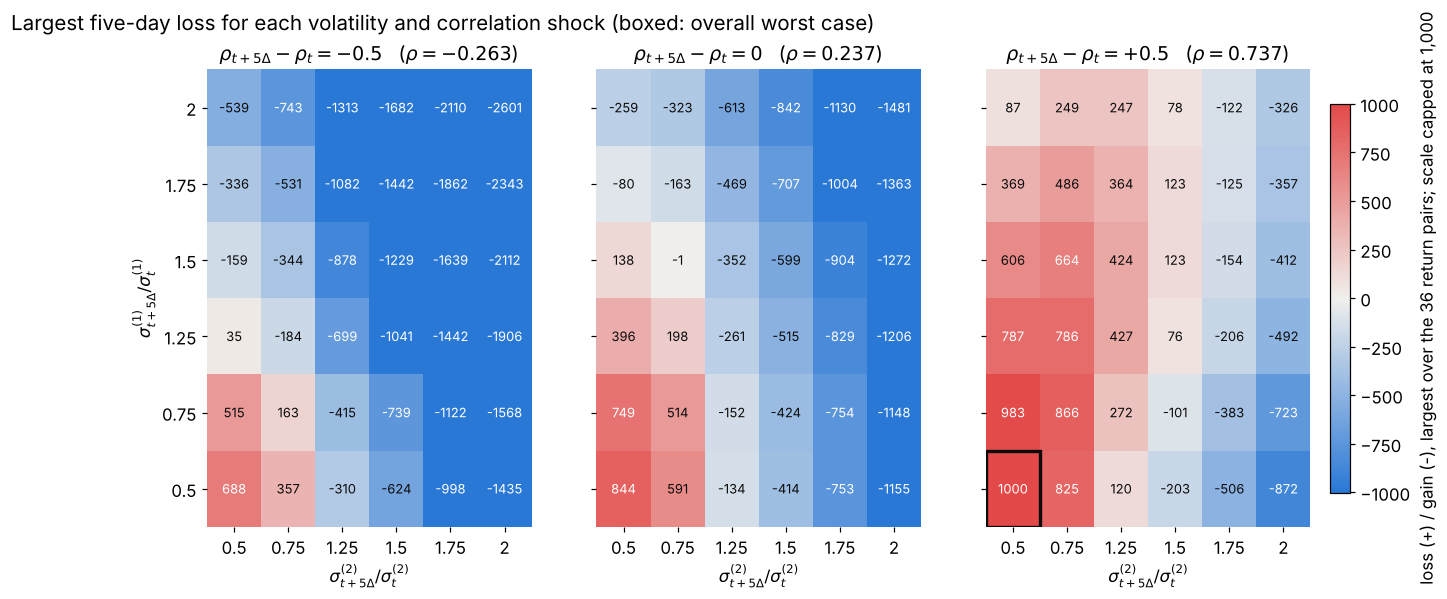

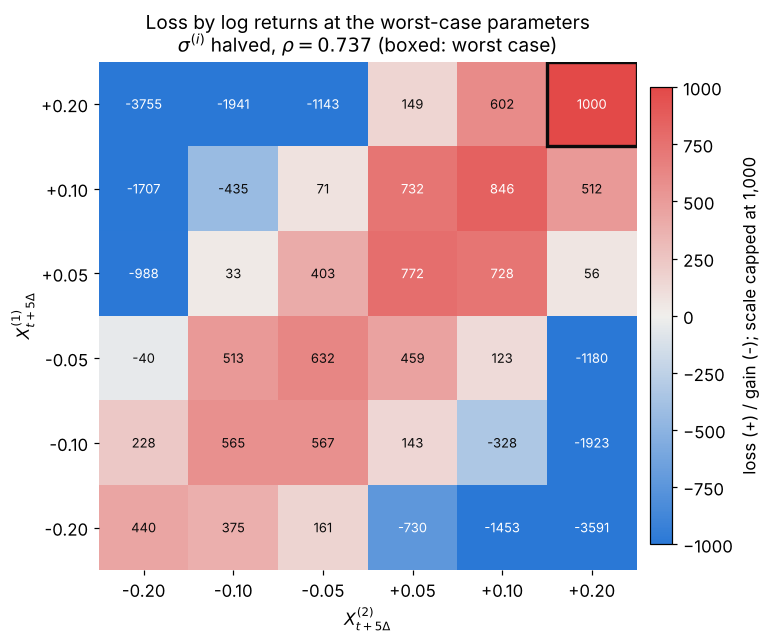

saved scenario_loss_by_vol_corr.png and scenario_loss_by_returns.png


In [9]:
def heat(ax, mat, xlabels, ylabels, norm, mark=None, fmt="{:.0f}"):
    im = ax.imshow(mat, cmap=DIVERGING, norm=norm, origin="lower", aspect="auto")
    ax.set_xticks(range(len(xlabels))); ax.set_xticklabels(xlabels)
    ax.set_yticks(range(len(ylabels))); ax.set_yticklabels(ylabels)
    for (a, b), v in np.ndenumerate(mat):
        dark = abs(norm(v) - 0.5) > 0.33
        ax.text(b, a, fmt.format(v), ha="center", va="center", fontsize=8.5,
                color="white" if dark else C_INK)
    if mark is not None:
        ax.add_patch(plt.Rectangle((mark[1] - 0.5, mark[0] - 0.5), 1, 1, fill=False, lw=2.2, ec=C_INK))
    for s in ax.spines.values():
        s.set_visible(False)
    return im


worst_by_vol = grid.groupby(["drho", "k1", "k2"]).loss.max()
vmax = float(grid.loss.max())
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)
fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.4), sharey=True)
klab = [f"{k:g}" for k in K_VALS]
for ax, d in zip(axes, D_VALS):
    mat = np.array([[worst_by_vol[(d, k1, k2)] for k2 in K_VALS] for k1 in K_VALS])
    mark = (K_VALS.index(worst.k1), K_VALS.index(worst.k2)) if d == worst.drho else None
    im = heat(ax, mat, klab, klab, norm, mark)
    dlab = "0" if d == 0 else f"{d:+.1f}"
    ax.set_title(rf"$\rho_{{t+5\Delta}}-\rho_t={dlab}$   ($\rho={RHO_T + d:.3f}$)")
    ax.set_xlabel(r"$\sigma^{(2)}_{t+5\Delta}/\sigma^{(2)}_t$")
axes[0].set_ylabel(r"$\sigma^{(1)}_{t+5\Delta}/\sigma^{(1)}_t$")
cb = fig.colorbar(im, ax=axes, shrink=0.85, pad=0.015)
cb.set_label("loss (+) / gain (-), largest over the 36 return pairs; scale capped at 1,000")
fig.suptitle("Largest five-day loss for each volatility and correlation shock "
             "(boxed: overall worst case)", x=0.01, ha="left", fontsize=13.5)
fig.savefig(FIG1, bbox_inches="tight")
plt.show()

mat2 = np.array([[grid[(grid.x1 == a) & (grid.x2 == b) & (grid.k1 == worst.k1) & (grid.k2 == worst.k2)
                       & (grid.drho == worst.drho)].loss.iloc[0] for b in X_VALS] for a in X_VALS])
fig, ax = plt.subplots(figsize=(7.6, 6.0))
xlab = [f"{x:+.2f}" for x in X_VALS]
im = heat(ax, mat2, xlab, xlab, norm, (X_VALS.index(worst.x1), X_VALS.index(worst.x2)))
ax.set_xlabel(r"$X^{(2)}_{t+5\Delta}$"); ax.set_ylabel(r"$X^{(1)}_{t+5\Delta}$")
ax.set_title(rf"Loss by log returns at the worst-case parameters" + "\n"
             rf"$\sigma^{{(i)}}$ halved, $\rho={worst.rho:.3f}$ (boxed: worst case)")
cb = fig.colorbar(im, ax=ax, shrink=0.9, pad=0.02)
cb.set_label("loss (+) / gain (-); scale capped at 1,000")
fig.savefig(FIG2, bbox_inches="tight")
plt.show()
print(f"saved {FIG1} and {FIG2}")

---
## 10. All numbers for the written PDF

In [10]:
line = "=" * 78
print(line); print("SUMMARY OF RESULTS"); print(line)
print(f"\n[AT t]   tau = {TAU0}, V = {V0:.6f}, h1 = {H1:.6f}, h2 = {H2:.6f}, V_t = {PORT_T:.6f}")
print(f"[GRID]   N = {len(grid)}, tau after 5 days = {TAU1:.6f}")
print(f"[(b)]    max l = {worst.loss:.4f} at X1 = {worst.x1:+.2f}, X2 = {worst.x2:+.2f}, "
      f"sigma1 = {worst.sigma1:.4f} ({worst.k1}x), sigma2 = {worst.sigma2:.4f} ({worst.k2}x), rho = {worst.rho:.3f}")
print(f"[(c)]    max w l = {best_w.wloss:.4f} at X1 = {best_w.x1:+.2f}, X2 = {best_w.x2:+.2f}, "
      f"sigma1 = {best_w.sigma1:.4f} ({best_w.k1}x), sigma2 = {best_w.sigma2:.4f} ({best_w.k2}x), "
      f"rho = {best_w.rho:.3f};  w = {best_w.w:.6f};  loss l = {best_w.loss:.4f}")
for lab, row in (("(b)", worst), ("(c)", best_w)):
    m_, p_ = split(row)
    print(f"[SPLIT {lab}] market move {m_:.4f}, vol & corr {p_:.4f}")
print(f"[OPTION AFTER 5 DAYS] worst case: V' = {float(option_value(TAU1, S_T[0]*np.exp(worst.x1), S_T[1]*np.exp(worst.x2), worst.sigma1, worst.sigma2, worst.rho)):.4f};"
      f" weighted maximiser: V' = {float(option_value(TAU1, S_T[0]*np.exp(best_w.x1), S_T[1]*np.exp(best_w.x2), best_w.sigma1, best_w.sigma2, best_w.rho)):.4f}")

SUMMARY OF RESULTS

[AT t]   tau = 0.25, V = 921.739866, h1 = -21.952543, h2 = 31.201877, V_t = -921.739866
[GRID]   N = 3888, tau after 5 days = 0.230159
[(b)]    max l = 1000.3617 at X1 = +0.20, X2 = +0.20, sigma1 = 0.1107 (0.5x), sigma2 = 0.1518 (0.5x), rho = 0.737
[(c)]    max w l = 1313.7859 at X1 = +0.05, X2 = +0.05, sigma1 = 0.1661 (0.75x), sigma2 = 0.2277 (0.75x), rho = 0.737;  w = 1.953125;  loss l = 672.6584
[SPLIT (b)] market move 47.5911, vol & corr 952.7706
[SPLIT (c)] market move 66.3057, vol & corr 606.3527
[OPTION AFTER 5 DAYS] worst case: V' = 329.5296; weighted maximiser: V' = 343.5987


---
## 11. Self-checks

In [11]:
checks = []
check = lambda name, ok: checks.append((name, bool(ok)))

check("closed-form price matches Monte Carlo of the risk-neutral expectation", abs(mc - V0) < 4 * se)
check("deltas match finite differences", abs(fd1 - H1) < 1e-6 and abs(fd2 - H2) < 1e-6)
check("Euler: s1 h1 + s2 h2 = 2V, so V_t = -V", abs(S_T[0] * H1 + S_T[1] * H2 - 2 * V0) < 1e-9)
check("3,888 scenarios, all distinct", len(grid) == 3888 and not grid.duplicated(["x1", "x2", "k1", "k2", "drho"]).any())
check("sheet's example weight is 15/128", abs(float(ex.w.iloc[0]) - 15 / 128) < 1e-12)
check("shocked correlations stay inside (-1, 1)", grid.rho.between(-1, 1, inclusive="neither").all())
# an independent loop over the grid, written from the problem statement
mx, arg, mxw, argw = -np.inf, None, -np.inf, None
for x1 in X_VALS:
    for x2 in X_VALS:
        for k1 in K_VALS:
            for k2 in K_VALS:
                for d in D_VALS:
                    s1n, s2n = S_T[0] * np.exp(x1), S_T[1] * np.exp(x2)
                    vt5 = option_value(TAU1, s1n, s2n, k1 * SIG_T[0], k2 * SIG_T[1], RHO_T + d) - H1 * s1n - H2 * s2n
                    l = -(vt5 - PORT_T)
                    w = W_X[round(abs(x1), 2)] * W_X[round(abs(x2), 2)] * W_K[k1] * W_K[k2] * W_D[d]
                    if l > mx: mx, arg = l, (x1, x2, k1, k2, d)
                    if w * l > mxw: mxw, argw = w * l, (x1, x2, k1, k2, d)
check("independent loop reproduces the worst case", abs(mx - worst.loss) < 1e-9
      and arg == (worst.x1, worst.x2, worst.k1, worst.k2, worst.drho))
check("independent loop reproduces the weighted measure", abs(mxw - best_w.wloss) < 1e-9
      and argw == (best_w.x1, best_w.x2, best_w.k1, best_w.k2, best_w.drho))
check("both maximisers are unique", n_ties == 1 and n_ties_w == 1)
check("figures written", FIG1.exists() and FIG2.exists())

for nm, ok in checks:
    print(f"  [{'PASS' if ok else 'FAIL'}]  {nm}")
assert all(ok for _, ok in checks), "some checks failed"
print("\nALL CHECKS PASSED")

  [PASS]  closed-form price matches Monte Carlo of the risk-neutral expectation
  [PASS]  deltas match finite differences
  [PASS]  Euler: s1 h1 + s2 h2 = 2V, so V_t = -V
  [PASS]  3,888 scenarios, all distinct
  [PASS]  sheet's example weight is 15/128
  [PASS]  shocked correlations stay inside (-1, 1)
  [PASS]  independent loop reproduces the worst case
  [PASS]  independent loop reproduces the weighted measure
  [PASS]  both maximisers are unique
  [PASS]  figures written

ALL CHECKS PASSED
